In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [2]:
# Load dataset
data = pd.read_csv("aqi_data.csv")

# Display first five records
data.head()

,Date,Time,PM2.5,PM10,NO2,CO,O3,SO2,AQI Value,AQI Category,Location
0,2026-01-01,08:00,96.03,159.31,40.67,1.73,29.89,11.06,130,Moderate,Nashik Road
1,2026-01-01,08:00,118.02,190.44,30.89,1.42,27.83,10.14,145,Moderate,Panchavati
2,2026-01-01,08:00,90.85,98.29,19.91,1.07,22.88,13.26,97,Satisfactory,Satpur
3,2026-01-01,08:00,67.49,115.51,47.82,1.18,32.61,6.30,106,Moderate,Gangapur Road
4,2026-01-01,12:00,53.91,120.87,17.95,0.98,26.59,10.83,77,Satisfactory,Nashik Road


In [3]:
# Display dataset information
data.info()

# Statistical summary
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 2880 entries, 0 to 2879
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          2880 non-null   str    
 1   Time          2880 non-null   str    
 2   PM2.5         2880 non-null   float64
 3   PM10          2880 non-null   float64
 4   NO2           2880 non-null   float64
 5   CO            2880 non-null   float64
 6   O3            2880 non-null   float64
 7   SO2           2880 non-null   float64
 8   AQI Value     2880 non-null   int64  
 9   AQI Category  2880 non-null   str    
 10  Location      2880 non-null   str    
dtypes: float64(6), int64(1), str(4)
memory usage: 347.9 KB


,PM2.5,PM10,NO2,CO,O3,SO2,AQI Value
count,2880.00000,2880.000000,2880.000000,2880.000000,2880.000000,2880.000000,2880.000000
mean,62.69150,119.911986,30.056747,1.071306,31.939674,12.036715,91.268403
std,20.00923,35.931092,9.008460,0.324493,9.107478,3.953908,21.686384
min,8.23000,33.480000,2.000000,0.100000,2.000000,1.000000,29.000000
25%,48.17000,94.540000,23.690000,0.840000,25.850000,9.450000,75.000000
50%,60.65500,114.950000,29.240000,1.035000,31.805000,12.020000,89.000000
75%,75.21000,140.935000,35.852500,1.280000,38.095000,14.642500,106.000000
max,139.17000,273.830000,62.630000,2.650000,62.400000,27.410000,178.000000


In [4]:
# Convert column names into lowercase
data.columns = data.columns.str.strip().str.lower()
data.columns = data.columns.str.replace(" ", "_")

# Rename common column names
data.rename(columns={
    'pm2_5': 'pm25',
    'pm2.5': 'pm25',
    'rspm': 'pm10',
    'from_date': 'date',
    'sampling_date': 'date',
    'station': 'location',
    'aqi': 'aqi_value'
}, inplace=True)

# Display column names
print(data.columns.tolist())

['date', 'time', 'pm25', 'pm10', 'no2', 'co', 'o3', 'so2', 'aqi_value', 'aqi_category', 'location']


In [5]:
# Check missing values
print("Missing values:")
print(data.isnull().sum())

# Select available pollutant columns
pollutants = ['pm25', 'pm10', 'no2', 'co', 'o3', 'so2']
pollutants = [col for col in pollutants if col in data.columns]

# Convert pollutants into numeric format
for col in pollutants:
    data[col] = pd.to_numeric(data[col], errors='coerce')

    # Fill missing values with column mean
    if data[col].notna().any():
        data[col] = data[col].fillna(data[col].mean())

print("\nMissing values after cleaning:")
print(data.isnull().sum())

Missing values:
date            0
time            0
pm25            0
pm10            0
no2             0
co              0
o3              0
so2             0
aqi_value       0
aqi_category    0
location        0
dtype: int64

Missing values after cleaning:
date            0
time            0
pm25            0
pm10            0
no2             0
co              0
o3              0
so2             0
aqi_value       0
aqi_category    0
location        0
dtype: int64


In [6]:
# Convert date into datetime format
data['date'] = pd.to_datetime(data['date'], errors='coerce')

# Extract year and month
data['year'] = data['date'].dt.year
data['month'] = data['date'].dt.month


print(data[['date', 'year', 'month']].head())

        date  year  month
0 2026-01-01  2026      1
1 2026-01-01  2026      1
2 2026-01-01  2026      1
3 2026-01-01  2026      1
4 2026-01-01  2026      1


In [7]:
# Identify seasons using month
def get_season(month):
    if month in [3, 4, 5]:
        return 'Summer'
    elif month in [6, 7, 8, 9]:
        return 'Monsoon'
    elif month in [10, 11]:
        return 'Post-Monsoon'
    else:
        return 'Winter'

data['season'] = data['month'].apply(get_season)

# Display seasonal averages
season_avg = data.groupby('season')[pollutants].mean()

print(season_avg)

              pm25        pm10        no2        co         o3        so2
season                                                                   
Monsoon  50.380496   97.679849  29.945065  1.079504  32.067931  12.172155
Summer   59.308628  113.540149  29.998179  1.069735  32.078906  11.863723
Winter   74.017659  140.775392  30.202966  1.069725  31.659523  12.239894


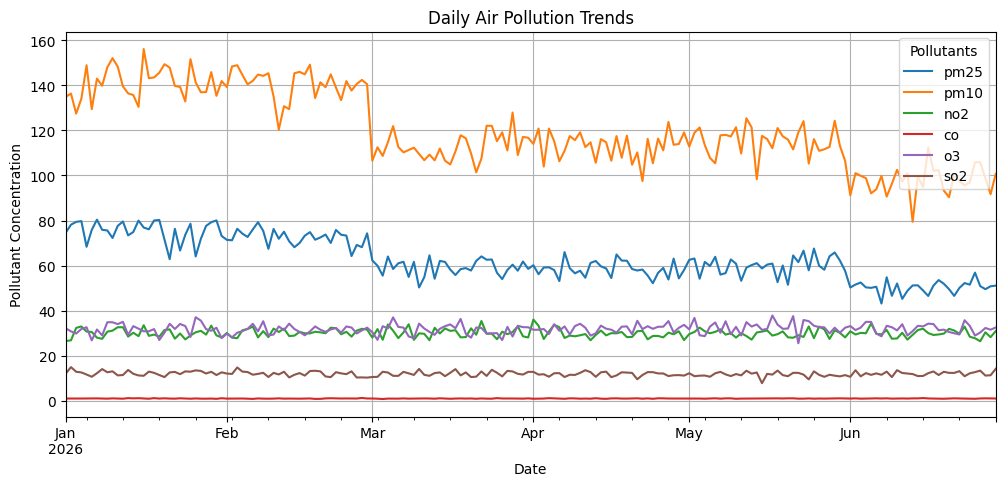

In [8]:
# Plot pollutant trends over time
daily_data = data.groupby('date')[pollutants].mean()

daily_data.plot(figsize=(12, 5))

plt.title('Daily Air Pollution Trends')
plt.xlabel('Date')
plt.ylabel('Pollutant Concentration')
plt.legend(title='Pollutants')
plt.grid()
plt.show()

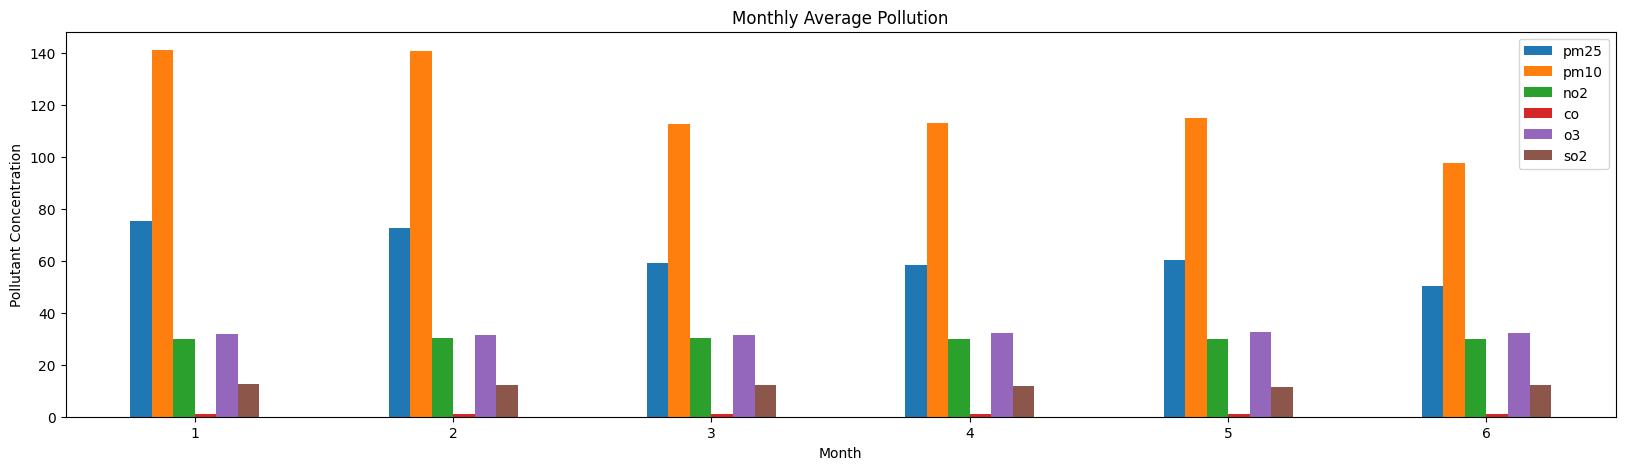

In [9]:
# Calculate monthly average pollution
monthly_data = data.groupby('month')[pollutants].mean()

# Plot monthly pollution
monthly_data.plot(kind='bar', figsize=(20,5))

plt.title('Monthly Average Pollution')
plt.xlabel('Month')
plt.ylabel('Pollutant Concentration')
plt.xticks(rotation=0)
plt.show()

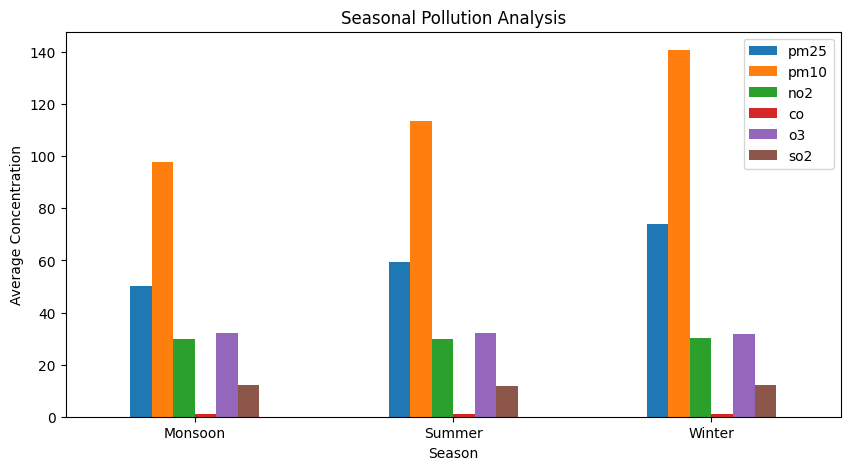

In [10]:
# Plot seasonal pollution
season_avg.plot(kind='bar', figsize=(10, 5))

plt.title('Seasonal Pollution Analysis')
plt.xlabel('Season')
plt.ylabel('Average Concentration')
plt.xticks(rotation=0)
plt.show()

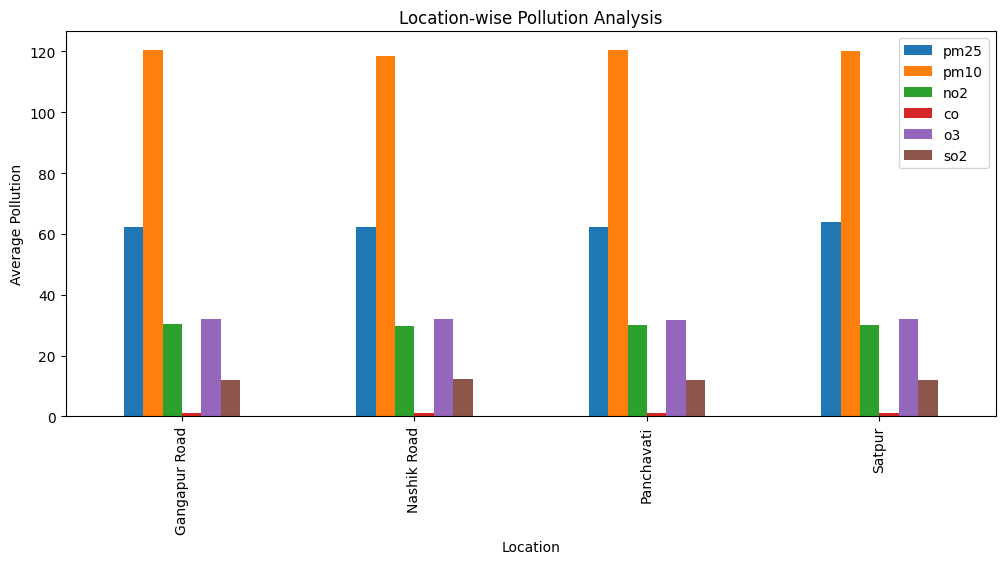

In [11]:
# Check location-wise pollution
if 'location' in data.columns:

    location_avg = data.groupby('location')[pollutants].mean()

    location_avg.plot(kind='bar', figsize=(12, 5))

    plt.title('Location-wise Pollution Analysis')
    plt.xlabel('Location')
    plt.ylabel('Average Pollution')
    plt.xticks(rotation=90)
    plt.show()

else:
    print("Location column is not available.")

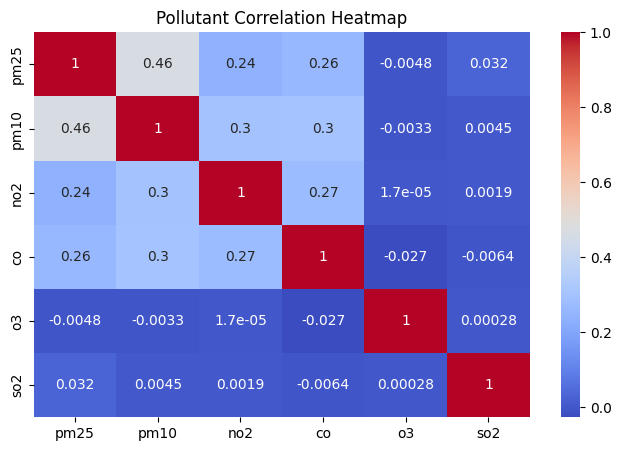

In [12]:
# Correlation between pollutants
plt.figure(figsize=(8, 5))

sns.heatmap(data[pollutants].corr(),
            annot=True, cmap='coolwarm')

plt.title('Pollutant Correlation Heatmap')
plt.show()

Average AQI: 91.26840277777778


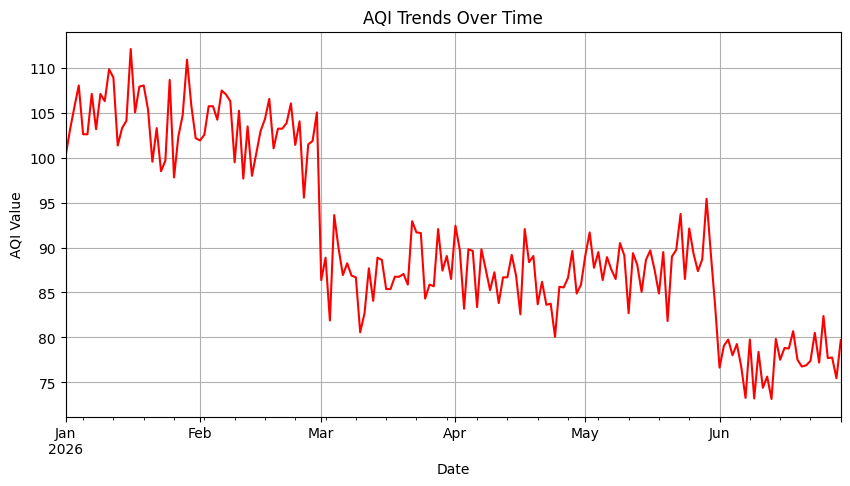

In [13]:
# Check AQI value
if 'aqi_value' in data.columns:

    data['aqi_value'] = pd.to_numeric(
        data['aqi_value'], errors='coerce'
    )

    print("Average AQI:", data['aqi_value'].mean())

    data.groupby('date')['aqi_value'].mean().plot(
        figsize=(10, 5), color='red'
    )

    plt.title('AQI Trends Over Time')
    plt.xlabel('Date')
    plt.ylabel('AQI Value')
    plt.grid()
    plt.show()

else:
    print("AQI Value column is not available in dataset.")

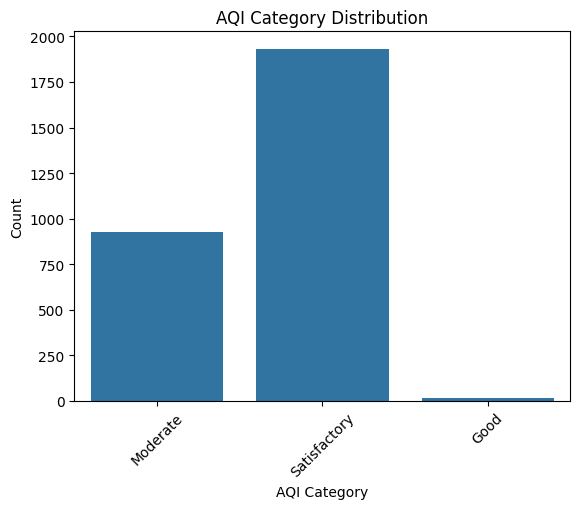

In [14]:
# Display AQI category distribution
if 'aqi_category' in data.columns:

    sns.countplot(data=data, x='aqi_category')

    plt.title('AQI Category Distribution')
    plt.xlabel('AQI Category')
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.show()

else:
    print("AQI Category column is not available.")

In [15]:
# Display cleaned dataset
print("Cleaned AQI Dataset:")
display(data.head())

# Display pollutant averages
print("\nAverage Pollutant Levels:")
print(data[pollutants].mean())

# Display highest pollutant levels
print("\nMaximum Pollutant Levels:")
print(data[pollutants].max())

print("\nAQI Analysis Completed Successfully!")

Cleaned AQI Dataset:


,date,time,pm25,pm10,no2,co,o3,so2,aqi_value,aqi_category,location,year,month,season
0,2026-01-01,08:00,96.03,159.31,40.67,1.73,29.89,11.06,130,Moderate,Nashik Road,2026,1,Winter
1,2026-01-01,08:00,118.02,190.44,30.89,1.42,27.83,10.14,145,Moderate,Panchavati,2026,1,Winter
2,2026-01-01,08:00,90.85,98.29,19.91,1.07,22.88,13.26,97,Satisfactory,Satpur,2026,1,Winter
3,2026-01-01,08:00,67.49,115.51,47.82,1.18,32.61,6.30,106,Moderate,Gangapur Road,2026,1,Winter
4,2026-01-01,12:00,53.91,120.87,17.95,0.98,26.59,10.83,77,Satisfactory,Nashik Road,2026,1,Winter



Average Pollutant Levels:
pm25     62.691500
pm10    119.911986
no2      30.056747
co        1.071306
o3       31.939674
so2      12.036715
dtype: float64

Maximum Pollutant Levels:
pm25    139.17
pm10    273.83
no2      62.63
co        2.65
o3       62.40
so2      27.41
dtype: float64

AQI Analysis Completed Successfully!
